In [1]:
import sys
import os

# Настройка пути
sys.path.insert(0, os.path.abspath('..'))

# Импорт сторонних библиотек
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_regression
from sklearn.model_selection import train_test_split
# Импорт своих модулей
from src.linear_regression import *
from src.scalers import StandardScaler
from src.metrics import mean_squared_error, r2_score


plt.style.use('ggplot')

In [2]:
def show_learning_plots(model, y_true, y_pred):
    test_mse, test_r2 = count_test(y_true, y_pred)
    fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(16, 6))
    ax[0].plot(model.losses_, lw=4, label='Train')
    ax[0].axhline(y=test_mse, lw=4, linestyle='--', c='black', label='Test')

    ax[1].plot(model.scores_, lw=4, label='Train')
    ax[1].axhline(y=test_r2, lw=4, linestyle='--', c='black', label='Test')

    ax[0].set_title('MSE (Scaled)')
    ax[1].set_title('R2-score')
    ax[0].legend()
    ax[1].legend()
    ax[2].bar(np.arange(1, model.w_.shape[0] + 1), model.w_)
    ax[2].set_title('Значения весов')
    plt.show()

def count_test(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    return mse, r2

In [3]:
X, y = make_regression(n_samples=40, n_features=50, n_informative=2, noise=25.0, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.15, random_state=42)

scaler_X = StandardScaler().fit(X_train)
X_train_scaled = scaler_X.transform(X_train)
X_test_scaled = scaler_X.transform(X_test)

scaler_y = StandardScaler().fit(y_train)
y_train_scaled = scaler_y.transform(y_train)
y_test_scaled = scaler_y.transform(y_test)

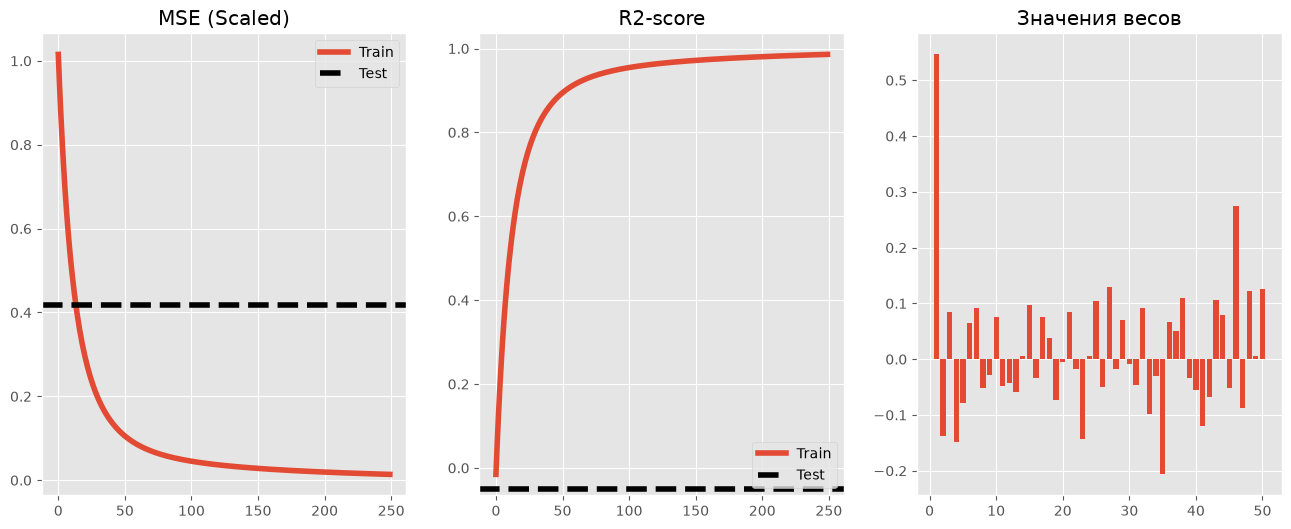

In [4]:
lr = LinearRegression(eta=0.01, n_iter=250)
lr.fit(X_train_scaled, y_train_scaled)
y_pred = lr.predict(X_test_scaled)
show_learning_plots(lr, y_test_scaled, y_pred)


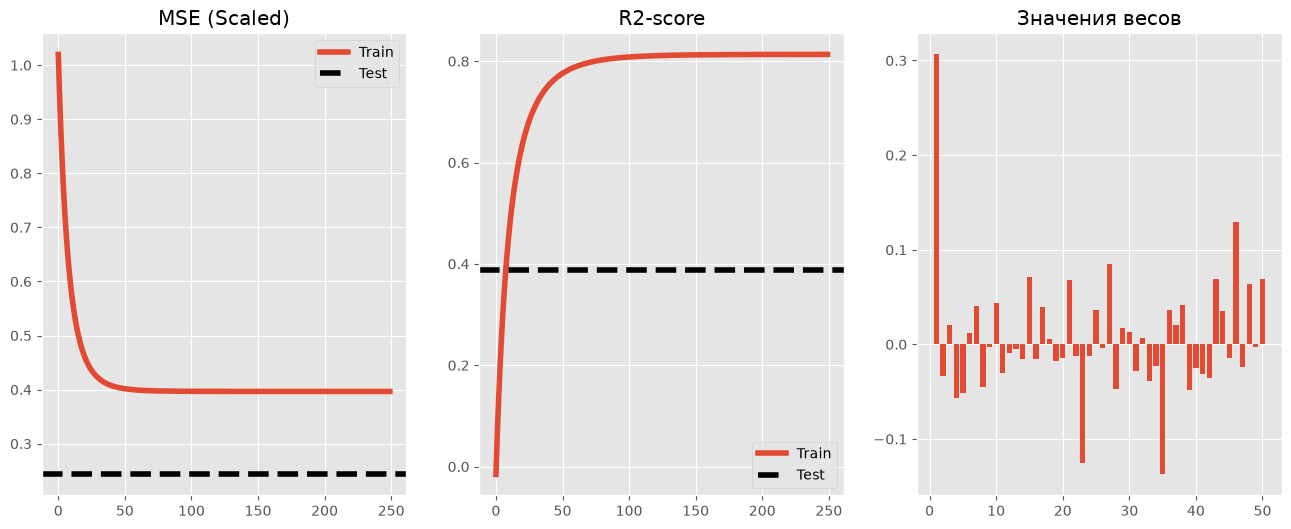

In [5]:
lr_l2 = Ridge(eta=0.01, n_iter=250, alpha=1)
lr_l2.fit(X_train_scaled, y_train_scaled)
y_pred = lr_l2.predict(X_test_scaled)
show_learning_plots(lr_l2, y_test_scaled, y_pred)


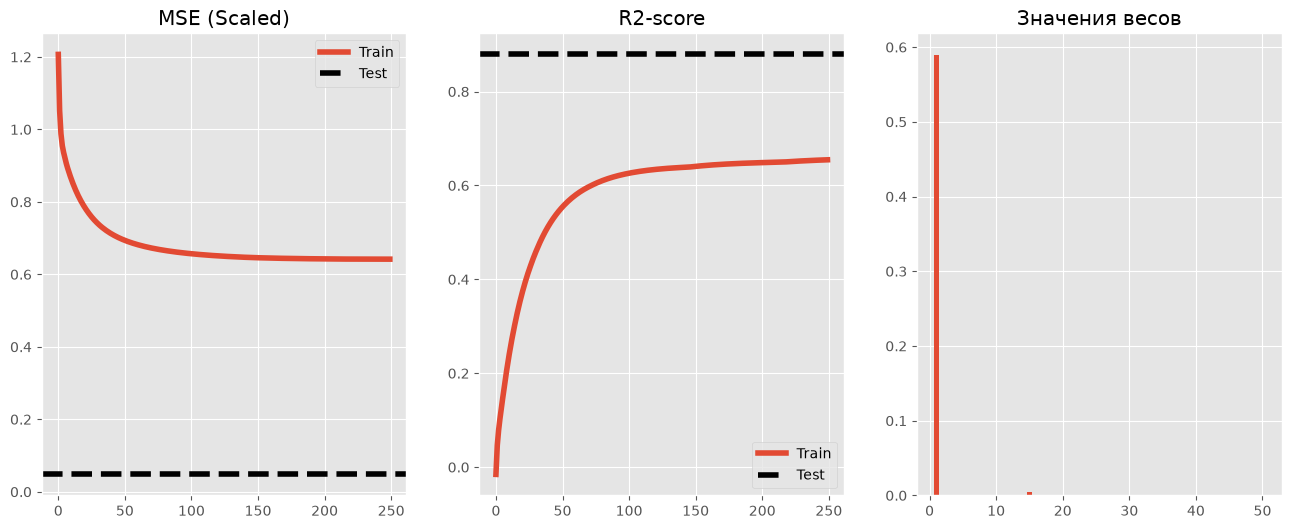

In [6]:
lr_l1 = Lasso(eta=0.01, n_iter=250, alpha=0.5)
lr_l1.fit(X_train_scaled, y_train_scaled)
y_pred = lr_l1.predict(X_test_scaled)
show_learning_plots(lr_l1, y_test_scaled, y_pred)


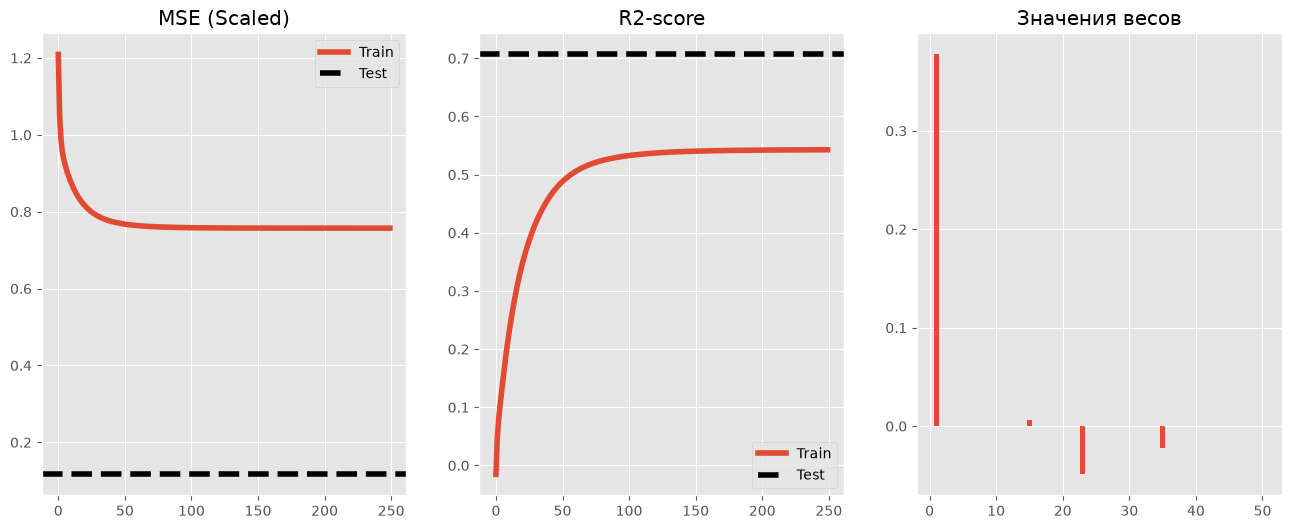

In [7]:
lr_EN = ElasticNet(eta=0.01, n_iter=250, alpha=1.0, l1_ratio=0.5)
lr_EN.fit(X_train_scaled, y_train_scaled)
y_pred = lr_EN.predict(X_test_scaled)
show_learning_plots(lr_EN, y_test_scaled, y_pred)